# Analyse des résultats 
Ce notebook ne fait **aucun entraînement** : il lit uniquement les petits fichiers JSON de `results/`
(copiés depuis le volume Modal `food101-ckpt`) et produit :

1. **Fig. 4** — accuracy *val* par epoch des 4 modèles (image, texte, late concat, early) ;
2. **Table VII** — accuracy test de nos 4 modèles à côté de l'article ;
3. **Table VI** — les 4 stratégies de late fusion à côté de l'article ;
4. **Early fusion** — moyenne ± écart-type sur 3 seeds.

Les figures sont sauvegardées en PNG dans `results/figures/`, les tables en CSV dans `results/`.

## 1. Imports et chemins

- Le notebook est dans `notebooks/`, donc les résultats sont dans `../results/`.
- `modal volume get food101-ckpt results results/` crée un sous-dossier `results/results/` quand
  `results/` existe déjà : `find_results_dir` regarde aux deux endroits et prend celui qui contient
  `image.json`.
- `FIG_DIR` est créé s'il n'existe pas (`exist_ok=True`, l'équivalent de `mkdir -p`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..")                       # project root, seen from notebooks/
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def find_results_dir(root: Path) -> Path:
    # results/ or results/results/ (nested copy from `modal volume get`)
    for candidate in (root / "results", root / "results" / "results"):
        if (candidate / "image.json").exists():
            return candidate
    raise FileNotFoundError("image.json not found in results/ or results/results/")


RESULTS_DIR = find_results_dir(ROOT)
print("results read from:", RESULTS_DIR.resolve())
print(sorted(p.name for p in RESULTS_DIR.glob("*.json")))

Matplotlib is building the font cache; this may take a moment.


results read from: /Users/zaynabez-zahraouy/Desktop/Advanced_deep_learning/project 1/codev1/results/results
['early.json', 'image.json', 'image_smoke.json', 'late_concat.json', 'late_max.json', 'late_sum.json', 'late_weighted.json', 'text.json', 'text_smoke.json']


## 2. Valeurs de l'article

Recopiées depuis le PDF (`articles/2020-IVCNZ-Gallo-Food101.pdf`), en accuracy (0–1) :

- **Table VII** (p. 5) : images 71,67 %, texte 84,41 %, late fusion 84,59 %, early fusion 92,50 %.
- **Table VI** (p. 5) : Sum 79,40 % (loss 1,24), Maximum 79,19 % (2,08),
  Weighted Ensemble 84,58 % (1,00), Concatenation 84,59 % (1,01).

Ces chiffres sont écrits **une seule fois** ici : toutes les tables plus bas les lisent dans ces
dictionnaires, ce qui évite les fautes de recopie.

In [2]:
PAPER_TABLE_VII = {"image": 0.7167, "text": 0.8441, "late_concat": 0.8459, "early": 0.9250}

PAPER_TABLE_VI = {   # merge mode -> (test acc, test loss)
    "sum": (0.7940, 1.24),
    "max": (0.7919, 2.08),
    "weighted": (0.8458, 1.00),
    "concat": (0.8459, 1.01),
}

## 3. Chargement des runs

- `load_run(name)` lit `results/<name>.json` : `config`, `history` (une ligne par epoch), et pour
  les fusions `best_epoch`, `best_val_acc`, `test_acc`, `test_loss`.
- **Accuracy test des modèles image et texte** : `train.py` ne touche jamais le test, donc
  `image.json` / `text.json` n'en ont pas. On la lit dans le JSON d'une fusion : `train_fusion.py` la
  calcule à partir des softmax en cache des `best.pt` (clé `baseline_test_acc`, ou
  `unimodal_test_acc` pour les runs lancés avant le renommage).
- **Contrôle de cohérence** : tous les runs de fusion doivent avoir été entraînés sur des features
  extraites des *mêmes* checkpoints (`feature_checkpoints`), sinon la comparaison n'a pas de sens.

In [3]:
def load_run(name: str) -> dict:
    with open(RESULTS_DIR / f"{name}.json") as f:
        return json.load(f)


def unimodal_test_acc(run: dict) -> dict:
    # image / text test accuracy stored by train_fusion.py (key renamed at some point)
    return run.get("baseline_test_acc") or run["unimodal_test_acc"]


runs = {name: load_run(name) for name in ("image", "text", "late_concat", "early")}
late_runs = {m: load_run(f"late_{m}") for m in PAPER_TABLE_VI}

fusion_runs = {**{f"late_{m}": r for m, r in late_runs.items()}, "early": runs["early"]}
checkpoints = {name: json.dumps(r["feature_checkpoints"], sort_keys=True) for name, r in fusion_runs.items()}
if len(set(checkpoints.values())) == 1:
    print("OK: all fusion runs use features from the same checkpoints:")
    print(" ", runs["early"]["feature_checkpoints"])
else:
    print("WARNING: fusion runs use features from different checkpoints:", checkpoints)

OK: all fusion runs use features from the same checkpoints:
  {'image': {'path': '/ckpt/image/best.pt', 'epoch': 24, 'val_acc': 0.7272727272727273}, 'text': {'path': '/ckpt/text/best.pt', 'epoch': 24, 'val_acc': 0.8487790526625478}}


## 4. Fig. 4 — accuracy val par epoch

- Une courbe par modèle : `history[i]["val_acc"]` en fonction de `history[i]["epoch"]`.
- Le point marque la **meilleure epoch sur val** : c'est celle dont les poids sont dans `best.pt` et
  qui sert à l'évaluation test.
- **Différence avec l'article** : la Fig. 4 de l'article trace l'accuracy *test* par epoch. Ici on
  trace le *val*, car le test ne doit servir qu'aux chiffres finaux (sinon regarder la courbe test
  pour choisir l'epoch revient à régler sur le test).
- Mêmes couleurs que l'article : image bleu, texte rouge, late vert, early violet.
- Les courbes n'ont pas la même longueur : chaque run s'arrête à `epochs` ou plus tôt par early
  stopping.

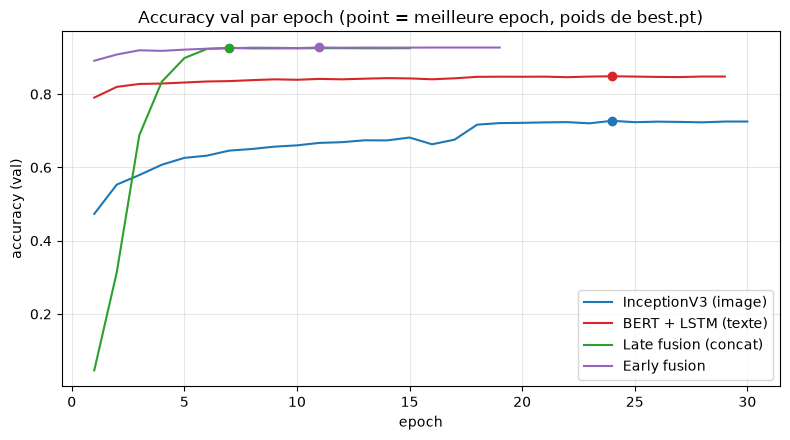

In [4]:
CURVES = {   # run name -> (label, color as in the paper's Fig. 4)
    "image": ("InceptionV3 (image)", "tab:blue"),
    "text": ("BERT + LSTM (texte)", "tab:red"),
    "late_concat": ("Late fusion (concat)", "tab:green"),
    "early": ("Early fusion", "tab:purple"),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (label, color) in CURVES.items():
    history = pd.DataFrame(runs[name]["history"])
    ax.plot(history["epoch"], history["val_acc"], color=color, label=label)
    best = history.loc[history["val_acc"].idxmax()]
    ax.scatter(best["epoch"], best["val_acc"], color=color, zorder=3)

ax.set_xlabel("epoch")
ax.set_ylabel("accuracy (val)")
ax.set_title("Accuracy val par epoch (point = meilleure epoch, poids de best.pt)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_val_accuracy.png", dpi=150)
plt.show()

## 5. Table VII — accuracy test des 4 modèles

- **Nous** : accuracy test calculée **une seule fois**, avec les poids de la meilleure epoch sur val.
  - image / texte : softmax en cache des `best.pt` (voir section 3) ;
  - late fusion = `late_concat` (le mode de l'article dans la Table VII) ;
  - early fusion = `early.json` (seed 42, même seed que les autres modèles ; voir section 7 pour la
    moyenne sur 3 seeds).
- `écart` = nous − article, en points de pourcentage.
- La table est aussi sauvegardée en CSV (`results/table_vii.csv`) pour le rapport.

In [5]:
unimodal = unimodal_test_acc(runs["early"])
ours = {
    "image": unimodal["image"],
    "text": unimodal["text"],
    "late_concat": runs["late_concat"]["test_acc"],
    "early": runs["early"]["test_acc"],
}
table_vii = pd.DataFrame({
    "modèle": ["Images (InceptionV3)", "Texte (BERT + LSTM)", "Late fusion (concat)", "Early fusion"],
    "nous (%)": [100 * ours[k] for k in PAPER_TABLE_VII],
    "article (%)": [100 * v for v in PAPER_TABLE_VII.values()],
})
table_vii["écart (pts)"] = table_vii["nous (%)"] - table_vii["article (%)"]
table_vii.to_csv(RESULTS_DIR / "table_vii.csv", index=False)
table_vii.round(2)

,modèle,nous (%),article (%),écart (pts)
0,Images (InceptionV3),72.16,71.67,0.49
1,Texte (BERT + LSTM),85.38,84.41,0.97
2,Late fusion (concat),92.72,84.59,8.13
3,Early fusion,92.70,92.50,0.20


## 6. Table VI — les 4 stratégies de late fusion

- Une ligne par mode de fusion (`late_<merge>.json`) : accuracy et loss test, plus l'epoch choisie
  sur val.
- `alpha` (mode `weighted` seulement) : poids appris sur le softmax **image**
  (le texte reçoit `1 − alpha`).
- Ligne supplémentaire **« moyenne (sans entraînement) »** : `(p_img + p_txt) / 2`, sans MLP. Elle
  n'est pas dans l'article, mais elle montre ce que le MLP de fusion apporte (ou non) par rapport à
  une simple moyenne.
- Les loss test ne sont comparables à l'article qu'à titre indicatif : même fonction
  (cross-entropy), mais des modèles de base différents.

In [6]:
MERGE_NAMES = {"sum": "Sum", "max": "Maximum", "weighted": "Weighted Ensemble", "concat": "Concatenation"}

rows = []
for merge, (paper_acc, paper_loss) in PAPER_TABLE_VI.items():
    run = late_runs[merge]
    rows.append({
        "fusion": MERGE_NAMES[merge],
        "nous acc (%)": 100 * run["test_acc"],
        "article acc (%)": 100 * paper_acc,
        "nous loss": run["test_loss"],
        "article loss": paper_loss,
        "best epoch (val)": run["best_epoch"],
        "alpha (image)": run.get("alpha"),
    })
average = unimodal_test_acc(runs["early"]).get("average")
if average is not None:
    rows.append({"fusion": "moyenne (sans entraînement)", "nous acc (%)": 100 * average})

table_vi = pd.DataFrame(rows)
table_vi["écart acc (pts)"] = table_vi["nous acc (%)"] - table_vi["article acc (%)"]
table_vi.to_csv(RESULTS_DIR / "table_vi.csv", index=False)
table_vi.round(3)

,fusion,nous acc (%),article acc (%),nous loss,article loss,best epoch (val),alpha (image),écart acc (pts)
0,Sum,93.102,79.40,0.430,1.24,8.0,NaN,13.702
1,Maximum,92.776,79.19,0.458,2.08,14.0,NaN,13.586
2,Weighted Ensemble,88.303,84.58,3.307,1.00,6.0,0.539,3.723
3,Concatenation,92.723,84.59,0.688,1.01,7.0,NaN,8.133
4,moyenne (sans entraînement),93.907,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Early fusion — moyenne ± écart-type sur 3 seeds

- Runs pris en compte : `early.json` (seed de la config, 42) et `early_seed<N>.json`
  (lancés avec `modal run modal_app.py::train_early --seed N`). Les doublons de seed sont ignorés.
- **Écart-type d'échantillon** (`ddof=1`, divise par n − 1) : avec seulement 3 valeurs, c'est
  l'estimateur standard ; l'écart-type « population » (n) le sous-estimerait.
- **Ce que la seed fait varier** : seulement l'initialisation du MLP de fusion et l'ordre des
  batches. Les features en cache (InceptionV3, BERT + LSTM) sont les mêmes pour les 3 runs, donc cet
  écart-type mesure la stabilité de la **tête de fusion**, pas celle de toute la chaîne
  (ré-entraîner les modèles de base avec d'autres seeds donnerait une variance plus grande).

In [7]:
early_runs = {}
for path in sorted(RESULTS_DIR.glob("early*.json")):
    run = json.loads(path.read_text())
    early_runs.setdefault(run["config"]["seed"], (path.name, run))   # one run per seed

seeds = pd.DataFrame([
    {"seed": seed, "fichier": name, "best epoch": run["best_epoch"],
     "val acc (%)": 100 * run["best_val_acc"], "test acc (%)": 100 * run["test_acc"]}
    for seed, (name, run) in sorted(early_runs.items())
])
print(seeds.round(2).to_string(index=False))

if len(seeds) < 3:
    print(f"\nOnly {len(seeds)} seed(s) found: run `modal run modal_app.py::train_early --seed 1` "
          "(and --seed 2), copy results/ again, then re-run this cell.")
mean, std = seeds["test acc (%)"].mean(), seeds["test acc (%)"].std(ddof=1)
print(f"\nEarly fusion, test acc over {len(seeds)} seed(s): {mean:.2f} ± {std:.2f} %"
      f"  (article: {100 * PAPER_TABLE_VII['early']:.2f} %, single run)")

 seed    fichier  best epoch  val acc (%)  test acc (%)
   42 early.json          11        92.73          92.7

Only 1 seed(s) found: run `modal run modal_app.py::train_early --seed 1` (and --seed 2), copy results/ again, then re-run this cell.

Early fusion, test acc over 1 seed(s): 92.70 ± nan %  (article: 92.50 %, single run)
